# NX-421 Mini-project — Part 2

## Multivariate pattern analysis methods (MVPA). 
The goal is to find spatial maps in a data-driven manner
(no GLM) and to investigate which maps would include the regions found in the GLM
analysis.
Project variant assigned to our group:
- Principal Component Analysis (variant 1)

## 0. Setup
### Imports

In [1]:
import os
import os.path as op
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
from nilearn.plotting import plot_stat_map, plot_roi
from sklearn.decomposition import PCA

%matplotlib inline

### Loading the data
Loading tfMRI_LANGUAGE_LR_mc.nii.gz, unsmoothed data, we want to avoid smoothing before PCA

In [2]:
data_path = './derivatives' 

img = nib.load(op.join(data_path,'func/tfMRI_LANGUAGE_LR_mc.nii.gz')) #TODO: correct the path 
affine = img.affine
data = np.asanyarray(img.dataobj)
data.shape 

(91, 109, 91, 316)

## 1. Applying PCA 
### Preprocessing 
We take the timepoints as being the “samples” and the voxels to be the features. 
We will first be removing useless voxels, such as ground ones, and flattening volume into a vector.

In [3]:
vol_shape = data.shape[:3]
n_vols = data.shape[-1]

In [4]:
first_volume = data[:, :, :, 0] # First volume

# Creating a mask to filter all voxels that aren't background, since the volume's background 
# voxels are the same as all following volumes we don't have to reproduce it for each volume
slice_non_background = first_volume > 500

# Vectorize : Taking only non-zero voxels into a vector 
samples = data[slice_non_background, :].T
samples.shape

#TODO: ASK TA, can we do the same as in lab and consider first volume to find background voxels ?

(316, 229345)

Next up we will be removing the spatial mean across timepoints from each timepoints. We calculate the mean spatial pattern and perform the substraction operation.

In [5]:
# Calculate the mean across columns
spatial_means = samples.mean(axis=0)

# Row means copied n_vols times so that we substract for each timepoint the spatial mean
row_means = np.tile(spatial_means, (n_vols, 1))
# Subtract the means for each row, put the result into X
X = samples - row_means

new_spatial_means = X.mean(axis=0) # Should be ~null  
print(new_spatial_means)

print("Should print True if each mean ≃ 0", np.allclose(new_spatial_means, 0, atol=1e-2))
#TODO: ASK TA, Is it the right way to verify ? the threshold is pretty weak compared to lab ?OK?

[ 6.5284439e-05  4.3844873e-05  1.1704843e-04 ...  5.4081784e-06
  1.2593329e-04 -6.7988527e-05]
Should print True if each mean ≃ 0 True


We can see that each timepoint new mean is near 0, which suggests that the spatial mean across timepoints has succesfully been removeds from each timepoint

In [6]:
X.shape

(316, 229345)

### Components Extraction

In [7]:
from sklearn.decomposition import PCA
nb_components = 10 # Arbitrary number

pca = PCA(n_components=nb_components)
pca.fit(X) # NOTE: Takes matrix of shape (nb_samples, nb_features)

,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",10
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linalg.svd` and select the components by postprocessing""covariance_eigh"" : Precompute the covariance matrix (on centered data), run a classical eigenvalue decomposition on the covariance matrix typically using LAPACK and select the components by postprocessing. This solver is very efficient for n_samples >> n_features and small n_features. It is, however, not tractable otherwise for large n_features (large memory footprint required to materialize the covariance matrix). Also note that compared to the ""full"" solver, this solver effectively doubles the condition number and is therefore less numerical stable (e.g. on input data with a large range of singular values).""arpack"" : Run SVD truncated to `n_components` calling ARPACK solver via `scipy.sparse.linalg.svds`. It requires strictly `0 < n_components < min(X.shape)`""randomized"" : Run randomized SVD by the method of Halko et al... versionadded:: 0.18.0.. versionchanged:: 1.5 Added the 'covariance_eigh' solver.",'auto'
,"tol tol: float, default=0.0Tolerance for singular values computed by svd_solver == 'arpack'.Must be of range [0.0, infinity)... versionadded:: 0.18.0",0.0
,"iterated_power iterated_power: int or 'auto', default='auto'Number of iterations for the power method computed bysvd_solver == 'randomized'.Must be of range [0, infinity)... versionadded:: 0.18.0",'auto'
,"n_oversamples n_oversamples: int, default=10This parameter is only relevant when `svd_solver=""randomized""`.It corresponds to the additional number of random vectors to sample therange of `X` so as to ensure proper conditioning. See:func:`~sklearn.utils.extmath.randomized_svd` for more details... versionadded:: 1.1",10
,"power_iteration_normalizer power_iteration_normalizer: {'auto', 'QR', 'LU', 'none'}, default='auto'Power iteration normalizer for randomized SVD

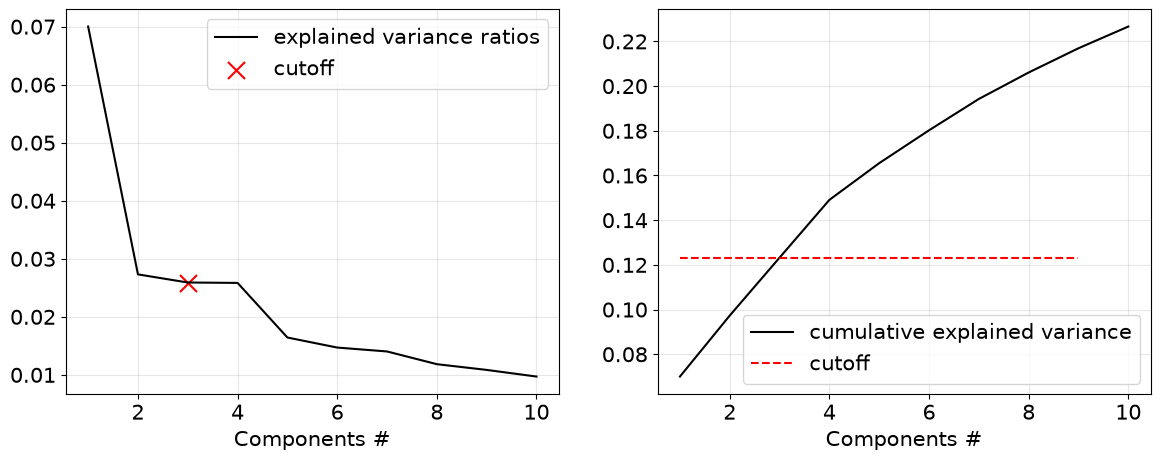

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(14,5))

ratios = pca.explained_variance_ratio_
cumulative_ratios = np.cumsum(pca.explained_variance_ratio_)
nb_clusters = 3

ax[0].plot(np.arange(1, len(ratios)+1), ratios, label='explained variance ratios', c='k')
ax[0].scatter([nb_clusters], [ratios[nb_clusters-1]], [150], marker='x', color='r', label='cutoff')
ax[1].plot(np.arange(1, len(cumulative_ratios)+1), cumulative_ratios, label='cumulative explained variance', c='k')
ax[1].hlines(y=cumulative_ratios[nb_clusters-1], xmin=1, xmax=len(ratios)-1, linestyle='--', color='r', label='cutoff')

for k in range(2):
    ax[k].set_xlabel('Components #', size=15)
    ax[k].legend(prop={'size':15})
    ax[k].tick_params(axis='both', which='major', labelsize=15)

    ax[k].grid(True, alpha=0.3)

In [12]:
pca_clusters = [] # List of spatial components (you should have in the list volumes)

for comp in pca.components_:
    # Create voxel of sample size 
    vol = np.zeros(vol_shape) 
    
    # Insert the 1D non-background voxel weights back into their 3D coordinates
    vol[slice_non_background] = comp
    
    # Append the reconstructed 3D volume to the list
    pca_clusters.append(vol) 

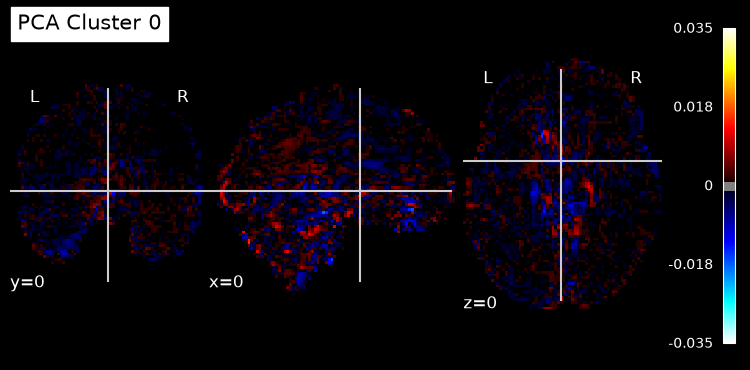

In [58]:
from nilearn.plotting import plot_stat_map

visual_idx = 0
plot_stat_map(nib.Nifti1Image(pca_clusters[visual_idx], affine), bg_img=None, threshold=1e-3,
               cut_coords=[0,0,0], black_bg=True, 
              title=f'PCA Cluster {visual_idx}')

plt.show()

#TODO: IS IT WHAT THEY MEAN BY 
#Show each of the selected PCA loadings separately, in axial view only.
#IF YES MODIFY TO ONLY SHOW AXIAL VIEW; Not the case right now 

# TODO NEXT
3. Compute the correlation between the (temporal) scores associated to the first
10 components and the regressors of the GLM you performed in Part 1
(including all regressors that you deem appropriate). Report the correlation
matrix and comment on the results, relating them to the spatial maps obtained
at point 2.